# Album Cover Matching — Training

Embedding + nearest-neighbour matching (see `handoff.md`). This notebook:

1. Loads the reference covers (`training_images/`) and labelled real photos (`Processed/`)
2. Measures a **zero-shot baseline** for DINOv2 and CLIP
3. Optionally **re-ranks** the top-k with SIFT + homography inliers
4. **Fine-tunes** the chosen backbone on synthetic "photo through a sleeve" augmentations
   of the covers, with a supervised contrastive loss
5. Saves the best checkpoint and gallery embeddings for deployment

Set `BACKBONE` in the config cell to switch models. Albums in `HELDOUT` are never trained on,
so their scores show how well the model handles covers added later without retraining.

## Setup

In [1]:
# One-time install into the kernel's environment (CUDA 12.8 build of PyTorch for the RTX 2060).
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cu128
%pip install transformers

Looking in indexes: https://download.pytorch.org/whl/cu128
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [1]:
import random
import re
from difflib import SequenceMatcher
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageOps
from pillow_heif import register_heif_opener
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import v2
from transformers import AutoImageProcessor, AutoModel, CLIPVisionModelWithProjection

register_heif_opener()

## Config

In [2]:
BACKBONE = "dinov2"  # "dinov2" or "clip"
MODEL_NAMES = {
    "dinov2": "facebook/dinov2-base",
    "clip": "openai/clip-vit-base-patch16",
}

GALLERY_DIR = Path("training_images")  # one reference cover per album ("Artist - Album.jpg")
QUERY_DIR = Path("Processed")          # real photos, already perspective-corrected
# Query file stem -> gallery file stem, for photos whose names don't auto-match
LABEL_OVERRIDES = {
    "Ella&Louis-Ella&Louis": "Ella Fitzgerald & Louis Armstrong - Ella & Louis",
}
CHECKPOINT_DIR = Path("checkpoints")

IMG_SIZE = 224
TOP_K = 5
SEED = 0
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Fine-tuning
HELDOUT_FRACTION = 0.15       # albums never trained on, to measure generalization to new covers
HOLD_OUT_QUERY_ALBUMS = True  # also keep albums with real test photos out of training
TRAIN_LAST_N_BLOCKS = 2       # transformer blocks to unfreeze; 0 = train only the projection head
EPOCHS = 20
BATCH_SIZE = 32               # albums per batch (x2 augmented views each)
REPEATS_PER_EPOCH = 4         # times each training album is sampled per epoch
BACKBONE_LR = 1e-5
HEAD_LR = 1e-4
TEMPERATURE = 0.07

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
print("device:", DEVICE)

device: cuda


## Data

Gallery labels come from filenames. Query photos are named like `ArtistName-AlbumName`, so both
sides are reduced to lowercase alphanumerics and matched exactly, then fuzzily (artist and album
must each be close, so a different album by the same artist doesn't match). Check the printed
mapping, and fix anything wrong in `LABEL_OVERRIDES`.

In [3]:
def normalize_key(text):
    return re.sub(r"[^a-z0-9]", "", text.lower().replace("&", "and"))


def load_image(path):
    """RGB PIL image with phone EXIF rotation applied (HEIC supported)."""
    return ImageOps.exif_transpose(Image.open(path)).convert("RGB")


gallery_paths = sorted(GALLERY_DIR.glob("*.jpg"))
gallery_names = [p.stem for p in gallery_paths]
gallery_keys = [normalize_key(n) for n in gallery_names]
key_to_idx = {k: i for i, k in enumerate(gallery_keys)}
gallery_parts = [[normalize_key(part) for part in n.split(" - ", 1)] for n in gallery_names]
print(f"{len(gallery_paths)} gallery covers")


def label_query(stem):
    """(gallery index, how it was matched) for a query photo, or (None, None)."""
    if stem in LABEL_OVERRIDES:
        return gallery_names.index(LABEL_OVERRIDES[stem]), "override"
    key = normalize_key(stem)
    if key in key_to_idx:
        return key_to_idx[key], "exact"
    artist, _, album = (normalize_key(part) for part in stem.partition("-"))

    def similarity(parts):
        return min(SequenceMatcher(None, a, b).ratio() for a, b in zip((artist, album), parts))

    scores = [similarity(parts) if len(parts) == 2 else 0 for parts in gallery_parts]
    best = int(np.argmax(scores)) if scores else None
    return (best, "FUZZY") if best is not None and scores[best] >= 0.8 else (None, None)


query_paths, query_labels = [], []
for path in sorted(QUERY_DIR.iterdir()):
    if path.suffix.lower() not in {".png", ".jpg", ".jpeg", ".heic"}:
        continue
    idx, how = label_query(path.stem)
    if idx is None:
        print(f"  SKIP {path.name}: no gallery cover (not downloaded, or add to LABEL_OVERRIDES)")
        continue
    query_paths.append(path)
    query_labels.append(idx)
    print(f"  {how:8} {path.name:45} -> {gallery_names[idx]}")
query_labels = torch.tensor(query_labels)
print(f"{len(query_paths)} labelled query photos")

1465 gallery covers
  FUZZY    50 Cent - Get Rich Or Die Tryin'.png          -> 50 Cent - Get Rich Or Die Trying
  FUZZY    A Tribe Called Quest - The Low End Theory.png -> Tribe Called Quest - The Low End Theory
  exact    ABBA - Gold.png                               -> ABBA - Gold
  exact    ACDC - Let There Be Rock.png                  -> AC_DC - Let There Be Rock
  exact    AliciaKeys-SongsInAMinor.png                  -> Alicia Keys - Songs In A Minor
  exact    Arctic Monkeys - The Car.png                  -> Arctic Monkeys - The Car
  exact    ArianaGrande-MyEverything.png                 -> Ariana Grande - My Everything
  exact    Bauhaus - The Bela Session.png                -> Bauhaus - The Bela Session
  exact    Beach House - Become.png                      -> Beach House - Become
  exact    Beach House - Bloom.png                       -> Beach House - Bloom
  exact    Beyonce-Renaissance.png                       -> Beyonce - Renaissance
  SKIP Bill Evans - Undercurrent.

## Model

In [4]:
class Embedder(nn.Module):
    """Pretrained backbone -> L2-normalized embedding, plus an optional trainable linear head.

    The head starts as the identity, so an untrained Embedder gives the zero-shot embedding.
    """

    def __init__(self, backbone=BACKBONE, use_head=True):
        super().__init__()
        self.backbone = backbone
        name = MODEL_NAMES[backbone]
        if backbone == "clip":
            self.model = CLIPVisionModelWithProjection.from_pretrained(name)
            dim = self.model.config.projection_dim
        else:
            self.model = AutoModel.from_pretrained(name)
            dim = self.model.config.hidden_size
        self.head = nn.Linear(dim, dim) if use_head else nn.Identity()
        if use_head:
            nn.init.eye_(self.head.weight)
            nn.init.zeros_(self.head.bias)
        processor = AutoImageProcessor.from_pretrained(name)
        self.mean, self.std = processor.image_mean, processor.image_std

    def forward(self, pixel_values):
        out = self.model(pixel_values=pixel_values)
        feats = out.image_embeds if self.backbone == "clip" else out.pooler_output
        return F.normalize(self.head(feats), dim=-1)

    def set_trainable(self, last_n_blocks):
        """Freeze the backbone except its last `last_n_blocks` blocks (+ final norm/projection)."""
        self.model.requires_grad_(False)
        if self.backbone == "clip":
            vision = self.model.vision_model
            blocks, final = vision.encoder.layers, [vision.post_layernorm, self.model.visual_projection]
        else:
            blocks, final = self.model.encoder.layer, [self.model.layernorm]
        if last_n_blocks > 0:
            for module in list(blocks[-last_n_blocks:]) + final:
                module.requires_grad_(True)
        self.head.requires_grad_(True)


def eval_transform(model):
    return v2.Compose([
        v2.ToImage(),
        v2.Resize((IMG_SIZE, IMG_SIZE), antialias=True),  # covers are square; squash, don't crop
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(model.mean, model.std),
    ])

## Embedding & evaluation

In [5]:
@torch.no_grad()
def embed_images(model, images, transform, batch_size=64):
    """Embed a list of paths, PIL images or tensors -> [N, D] tensor on the CPU."""
    model.eval()
    out = []
    for i in range(0, len(images), batch_size):
        batch = [load_image(x) if isinstance(x, Path) else x for x in images[i:i + batch_size]]
        pixels = torch.stack([transform(im) for im in batch]).to(DEVICE)
        with torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
            out.append(model(pixels).float().cpu())
    return torch.cat(out)


def retrieval_metrics(query_emb, gallery_emb, labels, query_names=None, k=TOP_K):
    """Top-1 / top-k accuracy. Prints each miss when `query_names` is given."""
    sims = query_emb @ gallery_emb.T
    top_scores, top_idx = sims.topk(k, dim=1)
    hit1 = top_idx[:, 0] == labels
    hitk = (top_idx == labels[:, None]).any(dim=1)
    if query_names is not None:
        for i in torch.nonzero(~hit1).flatten().tolist():
            rank = (sims[i] > sims[i, labels[i]]).sum().item() + 1
            print(f"  miss {query_names[i]}: predicted {gallery_names[top_idx[i, 0]]} "
                  f"({top_scores[i, 0]:.3f}); true cover is rank {rank} ({sims[i, labels[i]]:.3f})")
    return {
        "top1": hit1.float().mean().item(),
        f"top{k}": hitk.float().mean().item(),
        # For choosing the "no confident match" threshold: correct matches should score above wrong ones.
        "score_right": top_scores[hit1, 0],
        "score_wrong": top_scores[~hit1, 0],
    }, top_idx


def evaluate_real(model, gallery_emb=None, verbose=True):
    transform = eval_transform(model)
    if gallery_emb is None:
        gallery_emb = embed_images(model, gallery_paths, transform)
    query_emb = embed_images(model, query_paths, transform)
    names = [p.name for p in query_paths] if verbose else None
    metrics, top_idx = retrieval_metrics(query_emb, gallery_emb, query_labels, names)
    return metrics, top_idx, gallery_emb


def summarize(metrics, label=""):
    right, wrong = metrics["score_right"], metrics["score_wrong"]
    line = f"{label} top1={metrics['top1']:.3f} top{TOP_K}={metrics[f'top{TOP_K}']:.3f}"
    if len(right):
        line += f" | right-match scores min={right.min():.3f} mean={right.mean():.3f}"
    if len(wrong):
        line += f" | wrong-match scores max={wrong.max():.3f}"
    print(line)

## Zero-shot baseline

Compares both backbones on the real photos with no training. If one is already good enough,
you can skip fine-tuning and just save its gallery embeddings (last section).

In [6]:
baseline = {}
for backbone in MODEL_NAMES:
    print(f"--- {backbone}")
    m = Embedder(backbone).to(DEVICE)
    metrics, top_idx, _ = evaluate_real(m)
    summarize(metrics, backbone)
    baseline[backbone] = (metrics, top_idx)
    del m
    torch.cuda.empty_cache()

--- dinov2


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  miss A Tribe Called Quest - The Low End Theory.png: predicted Bruno Mars - 24K Magic (0.384); true cover is rank 43 (0.238)
  miss ABBA - Gold.png: predicted Freddie Redd Quintet - Shades Of Reed (0.403); true cover is rank 256 (0.152)
  miss AliciaKeys-SongsInAMinor.png: predicted Beastie Boys - Root Down (0.511); true cover is rank 225 (0.253)
  miss Bauhaus - The Bela Session.png: predicted Miles Davis - Sketches Of Spain Mono (0.503); true cover is rank 117 (0.292)
  miss Beach House - Become.png: predicted Bob Marley - Exodus (0.434); true cover is rank 4 (0.386)
  miss CannonballAdderley-Somethin'Else.png: predicted Kenny Dorham - Trompeta Toccata (0.502); true cover is rank 1033 (0.050)
  miss CharlieXCX-Brat.png: predicted Bob Marley - Exodus (0.509); true cover is rank 51 (0.160)
  miss DonnyHathaway-Live.png: predicted Roots - The Tipping Point (0.576); true cover is rank 4 (0.498)
  miss Justin Bieber - My World 2.0.png: predicted Nick Cave & Bad Seeds - Tender Prey (0.584

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] CLIPVisionModelWithProjection LOAD REPORT from: openai/clip-vit-base-patch16
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.mlp.fc1.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0

  miss Arctic Monkeys - The Car.png: predicted Association - The Association (0.770); true cover is rank 2 (0.741)
  miss Bauhaus - The Bela Session.png: predicted Bauhaus - Mask (0.739); true cover is rank 2 (0.735)
  miss Beach House - Become.png: predicted Association - The Association (0.770); true cover is rank 11 (0.665)
  miss Beach House - Bloom.png: predicted Khruangbin & Friends - Live At Stubb's (0.672); true cover is rank 49 (0.574)
  miss FleetwoodMac-TangoInTheNight.png: predicted Association - The Association (0.752); true cover is rank 205 (0.509)
  miss HarryStyles-Harry'sHouse.png: predicted Harry Styles - Harry Styles (0.730); true cover is rank 4 (0.674)
  miss JoyDivision-Preston28February1980.png: predicted C418 - Minecraft Volume Alpha (0.694); true cover is rank 3 (0.662)
  miss KanyeWest-808s&HeartBreak.png: predicted Kanye West - Late Registration (0.780); true cover is rank 2 (0.725)
  miss Linkin Park - From Zero.png: predicted Linkin Park - Hybrid Theory (0

## Optional: SIFT re-ranking

Covers are flat, so a correct match shares many keypoints that agree on one homography.
Re-checking only the top-k embedding matches keeps this cheap. It's tolerant of glare and hands
(they only remove some keypoints) and also works on photos that weren't perspective-corrected.

In [7]:
sift = cv2.SIFT_create(nfeatures=2000)
_sift_cache = {}


def sift_features(path, max_side=800):
    if path not in _sift_cache:
        gray = np.array(load_image(path).convert("L"))
        scale = max_side / max(gray.shape)
        if scale < 1:
            gray = cv2.resize(gray, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
        keypoints, descriptors = sift.detectAndCompute(gray, None)
        points = np.float32([kp.pt for kp in keypoints])
        _sift_cache[path] = (points, descriptors)
    return _sift_cache[path]


def homography_inliers(query_path, gallery_path, ratio=0.75):
    q_pts, q_des = sift_features(query_path)
    g_pts, g_des = sift_features(gallery_path)
    if q_des is None or g_des is None or len(q_pts) < 4 or len(g_pts) < 4:
        return 0
    pairs = cv2.BFMatcher().knnMatch(q_des, g_des, k=2)
    good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
    if len(good) < 4:
        return 0
    src = q_pts[[m.queryIdx for m in good]]
    dst = g_pts[[m.trainIdx for m in good]]
    _, mask = cv2.findHomography(src, dst, cv2.RANSAC, 5.0)
    return int(mask.sum()) if mask is not None else 0


def rerank(query_paths, top_idx, min_inliers=15):
    """New top-1 per query: the candidate with most inliers, if it clears `min_inliers`."""
    new_top1 = []
    for query, candidates in zip(query_paths, top_idx.tolist()):
        inliers = [homography_inliers(query, gallery_paths[c]) for c in candidates]
        best = int(np.argmax(inliers))
        new_top1.append(candidates[best] if inliers[best] >= min_inliers else candidates[0])
    return torch.tensor(new_top1)


for backbone, (metrics, top_idx) in baseline.items():
    reranked = rerank(query_paths, top_idx)
    print(f"{backbone}: top1 {metrics['top1']:.3f} -> {(reranked == query_labels).float().mean():.3f} after SIFT re-rank")

dinov2: top1 0.717 -> 0.849 after SIFT re-rank
clip: top1 0.792 -> 0.868 after SIFT re-rank


## Augmentations: simulating a photo through a sleeve

Turns a clean cover into something like a real submission: perspective, cut-off edges,
glare streaks, washed-out contrast from the plastic, blur, JPEG, and an occluding "hand".
Run the preview cell and tune until the samples look like your real photos.

In [8]:
class SleeveGlare:
    """Adds 1-3 soft, elongated white highlights plus a mild haze, like light on a plastic sleeve."""

    def __init__(self, p=0.8, max_streaks=3, max_haze=0.25):
        self.p, self.max_streaks, self.max_haze = p, max_streaks, max_haze

    def __call__(self, img):  # float tensor [3, H, W] in [0, 1]
        if random.random() > self.p:
            return img
        _, h, w = img.shape
        yy, xx = torch.meshgrid(torch.linspace(0, 1, h), torch.linspace(0, 1, w), indexing="ij")
        glare = torch.zeros(h, w)
        for _ in range(random.randint(1, self.max_streaks)):
            cx, cy = random.random(), random.random()
            angle = random.uniform(0, np.pi)
            u = (xx - cx) * np.cos(angle) + (yy - cy) * np.sin(angle)
            v = -(xx - cx) * np.sin(angle) + (yy - cy) * np.cos(angle)
            length, width = random.uniform(0.1, 0.6), random.uniform(0.01, 0.12)
            glare += random.uniform(0.4, 1.0) * torch.exp(-(u / length) ** 2 - (v / width) ** 2)
        haze = random.uniform(0, self.max_haze)
        img = img * (1 - haze) + haze  # plastic lowers contrast
        return (img + glare.clamp(0, 1)).clamp(0, 1)


# PIL cover -> float tensor [3, IMG_SIZE, IMG_SIZE] in [0, 1] (not normalized)
sleeve_photo_aug = v2.Compose([
    v2.ToImage(),
    v2.RandomPerspective(distortion_scale=0.3, p=0.7),
    v2.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0), ratio=(0.7, 1.1), antialias=True),  # cut-off edges
    v2.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.03),
    v2.RandomApply([v2.GaussianBlur(9, sigma=(0.1, 2.0))], p=0.4),
    v2.JPEG(quality=(40, 95)),
    v2.ToDtype(torch.float32, scale=True),
    SleeveGlare(),
    v2.RandomErasing(p=0.3, scale=(0.02, 0.15), value=0),  # stand-in for a hand / sticker
])

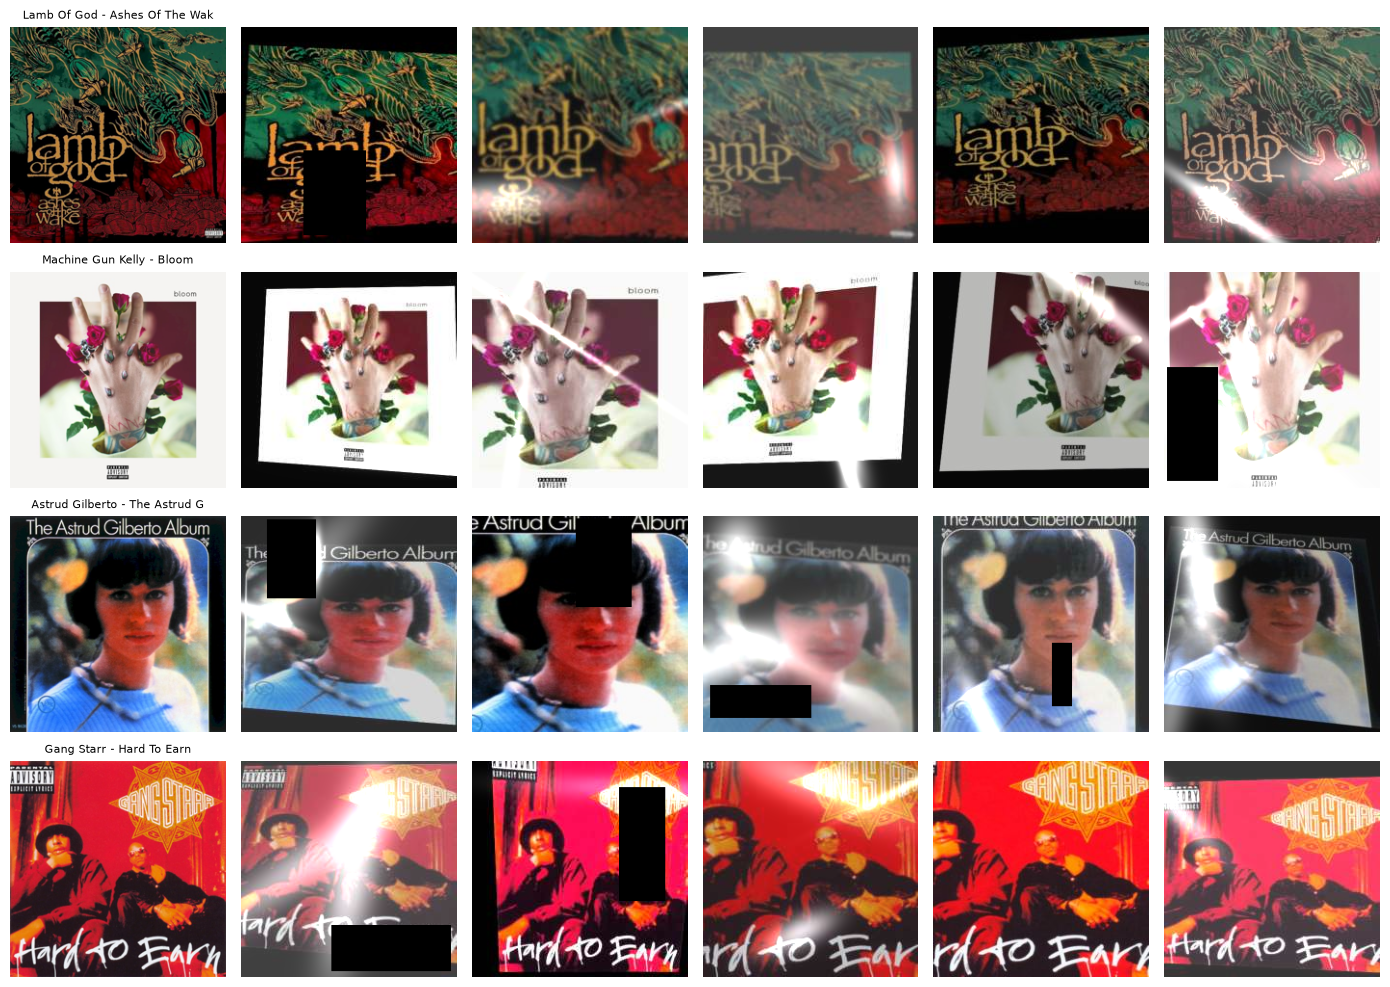

In [9]:
# Preview: each row is one cover, then several augmented versions of it
preview = random.sample(gallery_paths, 4)
fig, axes = plt.subplots(len(preview), 6, figsize=(14, 2.5 * len(preview)))
for row, path in zip(axes, preview):
    cover = load_image(path)
    row[0].imshow(cover.resize((IMG_SIZE, IMG_SIZE)))
    row[0].set_title(path.stem[:30], fontsize=8)
    for ax in row[1:]:
        ax.imshow(sleeve_photo_aug(cover).permute(1, 2, 0))
    for ax in row:
        ax.axis("off")
plt.tight_layout()

## Train / held-out split

In [10]:
rng = random.Random(SEED)
all_albums = list(range(len(gallery_paths)))
heldout = set(rng.sample(all_albums, int(HELDOUT_FRACTION * len(all_albums))))
if HOLD_OUT_QUERY_ALBUMS:
    heldout |= set(query_labels.tolist())
train_albums = [a for a in all_albums if a not in heldout]
heldout_albums = sorted(heldout)
print(f"{len(train_albums)} training albums, {len(heldout_albums)} held out")

1200 training albums, 265 held out


In [11]:
class CoverViews(Dataset):
    """Two independently augmented "photos" of the same cover, labelled by gallery index."""

    def __init__(self, albums, transform, repeats=1, cache_size=320):
        self.items = list(albums) * repeats
        self.transform = transform
        # Decode each cover once; augmentation happens on the cached copy.
        self.covers = {a: load_image(gallery_paths[a]).resize((cache_size, cache_size)) for a in set(albums)}

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        album = self.items[i]
        cover = self.covers[album]
        return self.transform(cover), self.transform(cover), album


def make_synthetic_queries(albums, views=2, seed=SEED):
    """Fixed augmented photos of `albums`, so held-out scores are comparable across epochs."""
    state = random.getstate(), torch.get_rng_state()
    random.seed(seed)
    torch.manual_seed(seed)
    images, labels = [], []
    for a in albums:
        cover = load_image(gallery_paths[a])
        for _ in range(views):
            images.append(sleeve_photo_aug(cover))
            labels.append(a)
    random.setstate(state[0])
    torch.set_rng_state(state[1])
    return images, torch.tensor(labels)


heldout_query_images, heldout_query_labels = make_synthetic_queries(heldout_albums)

## Loss

Supervised contrastive (SupCon): every view is pulled toward other views of the same cover
and pushed away from all other covers in the batch. Duplicate albums in a batch are handled,
since all views sharing a label count as positives.

In [12]:
def supcon_loss(z_a, z_b, labels, temperature=TEMPERATURE):
    z = torch.cat([z_a, z_b])
    labels = torch.cat([labels, labels])
    sims = z @ z.T / temperature
    self_mask = torch.eye(len(z), dtype=torch.bool, device=z.device)
    sims = sims.masked_fill(self_mask, float("-inf"))
    positives = (labels[:, None] == labels[None, :]) & ~self_mask
    log_prob = sims - sims.logsumexp(dim=1, keepdim=True)
    log_prob = log_prob.masked_fill(self_mask, 0)
    return (-(log_prob * positives).sum(1) / positives.sum(1)).mean()

## Fine-tune

In [13]:
model = Embedder(BACKBONE).to(DEVICE)
model.set_trainable(TRAIN_LAST_N_BLOCKS)
normalize = v2.Normalize(model.mean, model.std)
train_transform = v2.Compose([sleeve_photo_aug, normalize])

# num_workers=0: classes defined in a notebook can't be pickled into worker processes on Windows.
train_loader = DataLoader(
    CoverViews(train_albums, train_transform, repeats=REPEATS_PER_EPOCH),
    batch_size=BATCH_SIZE, shuffle=True, drop_last=True, num_workers=0,
)

backbone_params = [p for p in model.model.parameters() if p.requires_grad]
optimizer = torch.optim.AdamW(
    [{"params": backbone_params, "lr": BACKBONE_LR}, {"params": model.head.parameters(), "lr": HEAD_LR}],
    weight_decay=0.05,
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS * len(train_loader))
scaler = torch.amp.GradScaler(enabled=DEVICE == "cuda")
print(f"trainable params: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

trainable params: 14,770,944


In [14]:
def run_eval(model):
    """Held-out synthetic retrieval (checkpoint selection) + real photos (reporting)."""
    gallery_emb = embed_images(model, gallery_paths, eval_transform(model))
    heldout_emb = embed_images(model, heldout_query_images, normalize)
    heldout_metrics, _ = retrieval_metrics(heldout_emb, gallery_emb, heldout_query_labels)
    real_metrics, _, _ = evaluate_real(model, gallery_emb, verbose=False)
    return heldout_metrics, real_metrics


def train_one_epoch(model):
    model.train()
    total = 0.0
    for view_a, view_b, labels in train_loader:
        view_a, view_b, labels = view_a.to(DEVICE), view_b.to(DEVICE), labels.to(DEVICE)
        with torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
            z_a, z_b = model(view_a), model(view_b)
        loss = supcon_loss(z_a.float(), z_b.float(), labels)
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        total += loss.item()
    return total / len(train_loader)

In [15]:
CHECKPOINT_DIR.mkdir(exist_ok=True)
best_path = CHECKPOINT_DIR / f"{BACKBONE}_best.pt"
history = []

heldout_metrics, real_metrics = run_eval(model)
summarize(heldout_metrics, "epoch 0 held-out")
summarize(real_metrics, "epoch 0 real    ")
best_score = heldout_metrics["top1"]
torch.save(model.state_dict(), best_path)

for epoch in range(1, EPOCHS + 1):
    loss = train_one_epoch(model)
    heldout_metrics, real_metrics = run_eval(model)
    history.append({"epoch": epoch, "loss": loss, "heldout_top1": heldout_metrics["top1"],
                    "real_top1": real_metrics["top1"]})
    print(f"epoch {epoch}: loss {loss:.4f}")
    summarize(heldout_metrics, "  held-out")
    summarize(real_metrics, "  real    ")
    if heldout_metrics["top1"] > best_score:
        best_score = heldout_metrics["top1"]
        torch.save(model.state_dict(), best_path)
        print(f"  saved {best_path}")

epoch 0 held-out top1=0.906 top5=0.968 | right-match scores min=0.349 mean=0.727 | wrong-match scores max=0.803
epoch 0 real     top1=0.717 top5=0.849 | right-match scores min=0.424 mean=0.688 | wrong-match scores max=0.621
epoch 1: loss 0.0709
  held-out top1=0.985 top5=0.998 | right-match scores min=0.377 mean=0.781 | wrong-match scores max=0.666
  real     top1=0.943 top5=0.943 | right-match scores min=0.317 mean=0.693 | wrong-match scores max=0.549
  saved checkpoints\dinov2_best.pt
epoch 2: loss 0.0457
  held-out top1=0.985 top5=0.998 | right-match scores min=0.397 mean=0.792 | wrong-match scores max=0.859
  real     top1=0.943 top5=0.943 | right-match scores min=0.321 mean=0.699 | wrong-match scores max=0.540
epoch 3: loss 0.0349
  held-out top1=0.985 top5=0.998 | right-match scores min=0.395 mean=0.800 | wrong-match scores max=0.869
  real     top1=0.943 top5=0.943 | right-match scores min=0.342 mean=0.702 | wrong-match scores max=0.505
epoch 4: loss 0.0337
  held-out top1=0.985

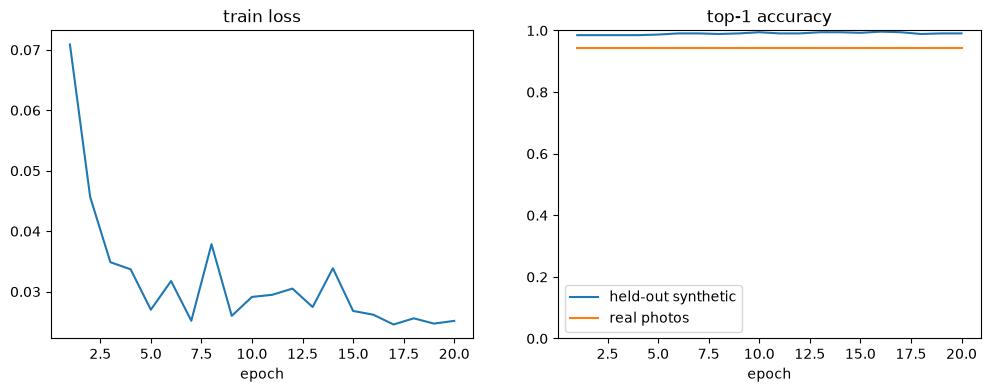

In [16]:
if history:
    epochs = [h["epoch"] for h in history]
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))
    ax_loss.plot(epochs, [h["loss"] for h in history])
    ax_loss.set(title="train loss", xlabel="epoch")
    ax_acc.plot(epochs, [h["heldout_top1"] for h in history], label="held-out synthetic")
    ax_acc.plot(epochs, [h["real_top1"] for h in history], label="real photos")
    ax_acc.set(title="top-1 accuracy", xlabel="epoch", ylim=(0, 1))
    ax_acc.legend()

## Final evaluation & export

Loads the best checkpoint, reports real-photo accuracy against the zero-shot baseline, and saves
the gallery embeddings. `match_photo` is the inference path: embed a (perspective-corrected)
photo and return the top matches.

In [17]:
model.load_state_dict(torch.load(best_path, map_location=DEVICE))
final_metrics, final_top_idx, gallery_emb = evaluate_real(model)
summarize(baseline[BACKBONE][0], f"{BACKBONE} zero-shot ")
summarize(final_metrics, f"{BACKBONE} fine-tuned")

export_path = CHECKPOINT_DIR / f"{BACKBONE}_gallery.npz"
np.savez(export_path, embeddings=gallery_emb.numpy(), names=np.array(gallery_names))
print(f"saved {export_path}")

  miss ABBA - Gold.png: predicted Rage Against The Machine - Renegades (0.393); true cover is rank 50 (0.191)
  miss CannonballAdderley-Somethin'Else.png: predicted Sonic Youth - Live In Austin 1988 (0.460); true cover is rank 923 (-0.018)
  miss CharlieXCX-Brat.png: predicted Strokes - Comedown Machine (0.487); true cover is rank 2 (0.431)
dinov2 zero-shot  top1=0.717 top5=0.849 | right-match scores min=0.424 mean=0.688 | wrong-match scores max=0.621
dinov2 fine-tuned top1=0.943 top5=0.962 | right-match scores min=0.387 mean=0.728 | wrong-match scores max=0.487
saved checkpoints\dinov2_gallery.npz


In [18]:
def match_photo(path, k=TOP_K, threshold=None):
    """Top-k (album, score) for a photo; empty list if the best score is below `threshold`."""
    query_emb = embed_images(model, [Path(path)], eval_transform(model))
    scores, idx = (query_emb @ gallery_emb.T)[0].topk(k)
    if threshold is not None and scores[0] < threshold:
        return []
    return [(gallery_names[i], round(s, 3)) for i, s in zip(idx.tolist(), scores.tolist())]


match_photo(query_paths[0])

[('50 Cent - Get Rich Or Die Trying', 0.834),
 ('Black Flag - Damaged', 0.394),
 ('Death - Individual Throught Patterns', 0.349),
 ('Ghost - Phantomime', 0.32),
 ('Post Malone - Beer Bongs & Bentleys', 0.312)]